# ACIT4620 Group 1 — Notebook 10: Hybrid CNN–ANFIS Explainability

**Research Question RQ3:** *How stable and faithful are class-specific Grad-CAM explanations and signed ANFIS rule contributions, especially for melanoma false negatives and images containing acquisition artifacts?*

Architecture **from the submitted proposal**: **image → frozen E2a-50 EfficientNet-B0 → 1280 pooled features → train-only scaler → 1280→8 learned projection → Gaussian membership rules (16) → first-order Sugeno affine consequents → 7 class logits**. This is **not** Mamdani postprocessing.

Interpretability tools are **not** part of the classification path. Grad-CAM gradients flow from the final *pre-Softmax ANFIS logit* back into the CNN's final spatial feature map. We also examine the CNN's original classifier head as a comparator, signed fuzzy-rule contributions, stability, and pixel-level blur-occlusion controls.

**Data discipline:** work only on the saved 1,441-image **validation** manifest; do **not** run on held-out test images/labels. This notebook does not train CNN or ANFIS. You must supply original HAM10000 JPEG files in `data/raw/`; extracted CNN features alone are insufficient for spatial explanations.

## 1. Environment and checkpoint / validation provenance

Use your VS Code Python environment with PyTorch, torchvision, pandas, NumPy, SciPy and matplotlib. The saved CNN and ANFIS checkpoints are included; no model download or new training is needed.

In [1]:

import sys
import torch
import torchvision
import numpy as np
import pandas as pd
import sklearn
from PIL import Image

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)
print("NumPy:", np.__version__)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")
print("PASS: Notebook 10 environment ready")


Python: c:\Users\grela\OneDrive\Desktop\OSLOMET\COMPUTATIONAL INTELLIGENCE\FOR FINAL REPORT\CODE\ACIT4620_E3_VSCode_Complete\.venv\Scripts\python.exe
PyTorch: 2.15.0+cpu
TorchVision: 0.29.2+cpu
NumPy: 2.5.4
Device: cpu
PASS: Notebook 10 environment ready


In [2]:
import sys
from pathlib import Path

# Works from the project root or from its parent extracted ZIP folder.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'hybrid_xai.py').is_file():
    candidate = PROJECT_ROOT / 'ACIT4620_10_CNN_ANFIS_XAI_VSCode'
    if (candidate / 'hybrid_xai.py').is_file():
        PROJECT_ROOT = candidate
assert (PROJECT_ROOT / 'hybrid_xai.py').exists(), 'Open the inner Notebook 10 project folder in VS Code.'
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from hybrid_xai import (
    verify_and_load, choose_validation_images, resolve_raw_image_files,
    check_prediction_reconstruction, generate_gradcam_explanations,
    evaluate_stability, evaluate_occlusion, finalize
)
import torch

print('Python:', sys.executable)
print('Notebook 10 root:', PROJECT_ROOT)
print('PyTorch:', torch.__version__)
session = verify_and_load(PROJECT_ROOT, device='cpu')


Python: c:\Users\grela\OneDrive\Desktop\OSLOMET\COMPUTATIONAL INTELLIGENCE\FOR FINAL REPORT\CODE\ACIT4620_E3_VSCode_Complete\.venv\Scripts\python.exe
Notebook 10 root: C:\Users\grela\OneDrive\Desktop\OSLOMET\COMPUTATIONAL INTELLIGENCE\FOR FINAL REPORT\CODE\Notebook_10_CNN_ANFIS_XAI_VSCode_Complete\ACIT4620_10_CNN_ANFIS_XAI_VSCode
PyTorch: 2.15.0+cpu
PASS: E2a-50 checkpoint SHA-256 2efbe67904bed16aec8fbf1f47e3af11f1a0136e7eab4a4c5cbd004edf9b9af9
PASS: three 16-rule ANFIS seeds (42/52/62), same split, class order and feature source
PASS: 1441 identical validation images, 1067 lesions
No held-out test images, labels or predictions are accessed.


## 2. Select a lesion-distinct validation-only analysis subset

We deliberately include melanoma **false negatives** and correctly recognized melanomas, along with examples of the other classes. This is an **exploratory purposive sample**, not an unbiased sampling estimate. If you have independently annotated acquisition artifacts, place documented rows in `data/artifact_annotations.csv`; the notebook will not fabricate annotations.

In [7]:
MAX_IMAGES = 13
selected = choose_validation_images(session, max_images=MAX_IMAGES)
print('Selected validation IDs:', selected.image_id.tolist())


Selected 13 validation images across 13 unique lesions
    image_id true_dx predicted_dx sample_group artifact_type
ISIC_0032152     mel        akiec  melanoma_FN              
ISIC_0026296     mel           nv  melanoma_FN              
ISIC_0026586     mel        akiec  melanoma_FN              
ISIC_0032072     mel           nv  melanoma_FN              
ISIC_0033129     mel          mel  melanoma_TP              
ISIC_0031953     mel          mel  melanoma_TP              
ISIC_0025783     mel          mel  melanoma_TP              
ISIC_0026253      nv           nv           nv              
ISIC_0030565     bkl          bkl          bkl              
ISIC_0027189     bcc          bcc          bcc              
ISIC_0033494   akiec        akiec        akiec              
ISIC_0033458    vasc          bcc         vasc              
ISIC_0026473      df          bkl           df              
NOTE: No image artifact labels available; do not claim an artifact-specific result.
Selecte

## 3. Locate original HAM10000 images

Download [HAM10000](https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000), then extract **both** `HAM10000_images_part_1` and `HAM10000_images_part_2` beneath `data/raw/`. The code loads **only** the selected saved validation IDs. This step intentionally raises a helpful error if the original images are absent.

In [8]:
image_paths = resolve_raw_image_files(session, selected)


PASS: 13 selected validation images found. No held-out test image decoded.


## 4. Mandatory reconstruction gate — CNN and ANFIS

The first saved validation probabilities must closely match the reconstructed CNN→ANFIS forward pass with correct deterministic ImageNet preprocessing and the original training-only scaler. **Do not disable this check** if it fails; otherwise gradients might explain the wrong model.

In [9]:
reconstruction = check_prediction_reconstruction(session, n_check=3, max_abs_tolerance=0.01)


    image_id head  max_abs_probability_error reconstructed_pred saved_pred
ISIC_0032152  cnn               1.537730e-03                bcc        bcc
ISIC_0032152   e4               1.733849e-06              akiec      akiec
ISIC_0026296  cnn               5.910289e-04                 nv         nv
ISIC_0026296   e4               7.651102e-08                 nv         nv
ISIC_0026586  cnn               2.106608e-03              akiec      akiec
ISIC_0026586   e4               5.821243e-07              akiec      akiec
PASS: saved CNN and ANFIS validation probabilities reproduced within 0.01.


## 5. Class-specific Grad-CAM and signed Sugeno-rule contributions

For each melanoma image, target the **melanoma** logit. For a melanoma false negative, also render the **incorrect predicted-class** attribution separately. For other diagnoses, target the selected ANFIS prediction. Compare maps from the original CNN classifier and hybrid ANFIS, using identical backbone spatial maps and target class. The second visualization plots positive/negative contributions of the 16 *learned* fuzzy rules to the selected logit.

Grad-CAM + signed rules: ISIC_0032152 target mel
Grad-CAM + signed rules: ISIC_0026296 target mel
Grad-CAM + signed rules: ISIC_0026586 target mel
Grad-CAM + signed rules: ISIC_0032072 target mel
Grad-CAM + signed rules: ISIC_0033129 target mel
Grad-CAM + signed rules: ISIC_0031953 target mel
Grad-CAM + signed rules: ISIC_0025783 target mel
Grad-CAM + signed rules: ISIC_0026253 target nv
Grad-CAM + signed rules: ISIC_0030565 target bkl
Grad-CAM + signed rules: ISIC_0027189 target bcc
Grad-CAM + signed rules: ISIC_0033494 target akiec
Grad-CAM + signed rules: ISIC_0033458 target bcc
Grad-CAM + signed rules: ISIC_0026473 target bkl
PASS: 13 matched validation-image explanations saved.
Rule contribution rows: 208
Saved Grad-CAM overlays to: C:\Users\grela\OneDrive\Desktop\OSLOMET\COMPUTATIONAL INTELLIGENCE\FOR FINAL REPORT\CODE\Notebook_10_CNN_ANFIS_XAI_VSCode_Complete\ACIT4620_10_CNN_ANFIS_XAI_VSCode\outputs\ACIT4620_10_Explainability_Validation\gradcam_overlays


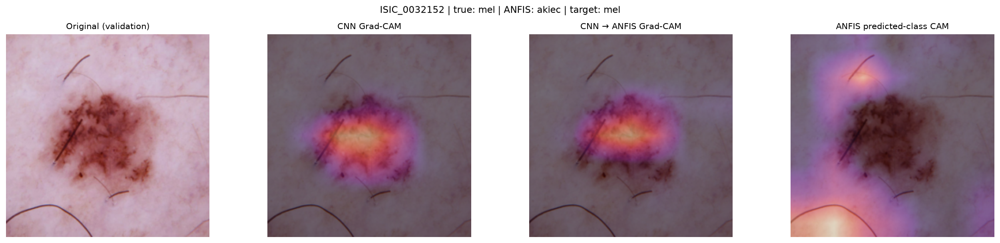

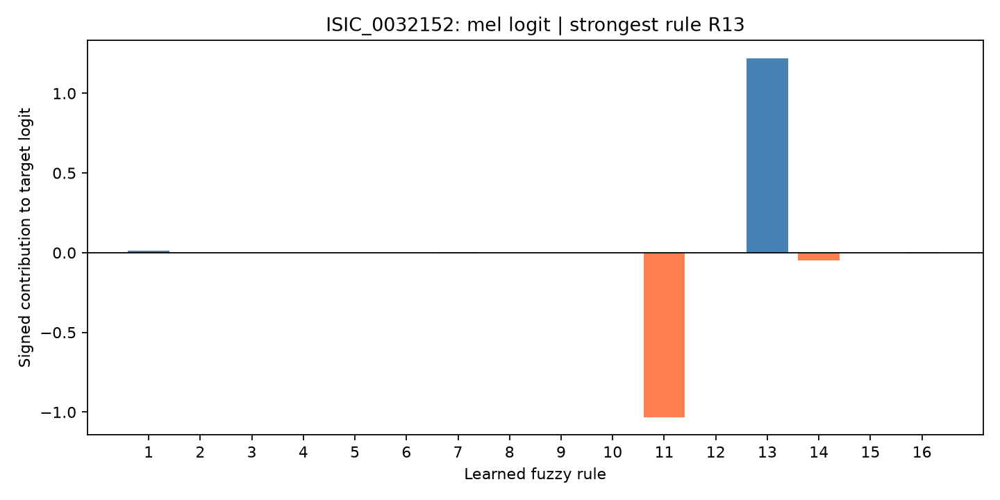

In [10]:
rule_details = generate_gradcam_explanations(session)
print('Rule contribution rows:', len(rule_details))
print('Saved Grad-CAM overlays to:', session.out / 'gradcam_overlays')
from IPython.display import display, Image as IPImage
example = selected.iloc[0].image_id
display(IPImage(filename=str(session.out / 'gradcam_overlays' / f'{example}.png')))
display(IPImage(filename=str(session.out / 'rule_contributions' / f'{example}.png')))



ISIC_0032152 — Melanoma false negative


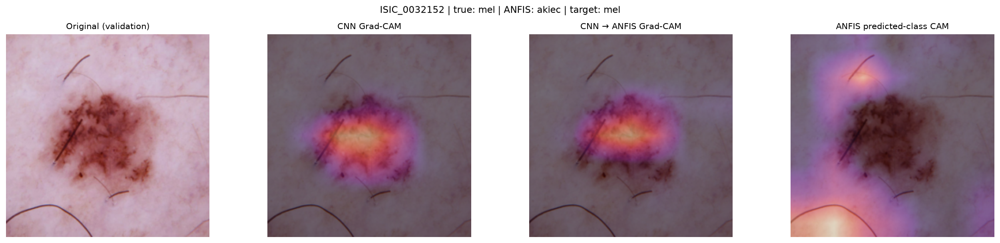


ISIC_0033129 — Correct melanoma prediction


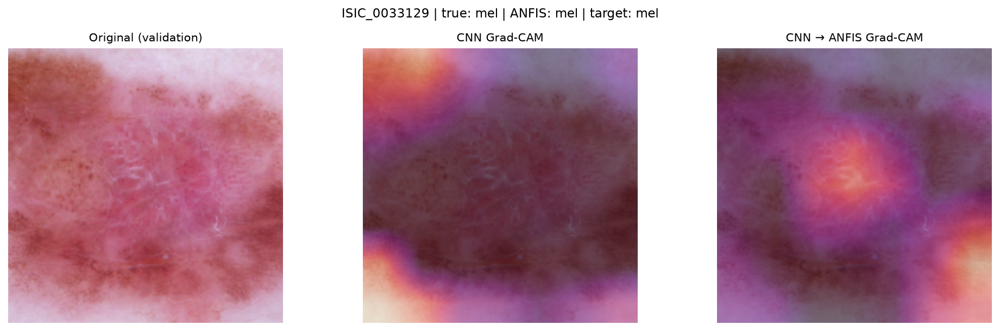


ISIC_0026253 — Correct nevus prediction


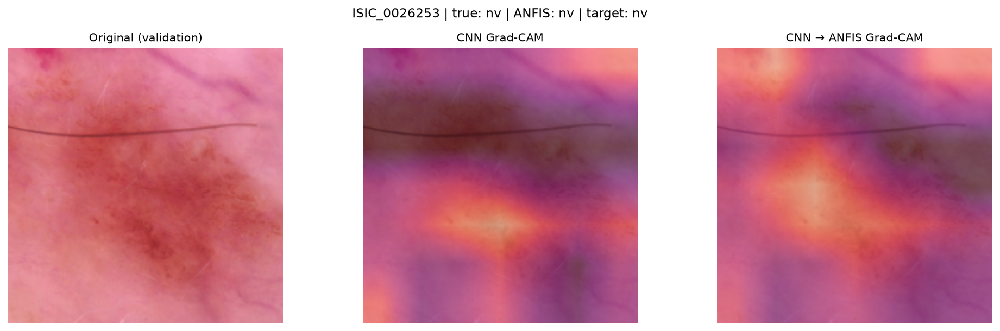


ISIC_0033458 — Vascular lesion misclassification


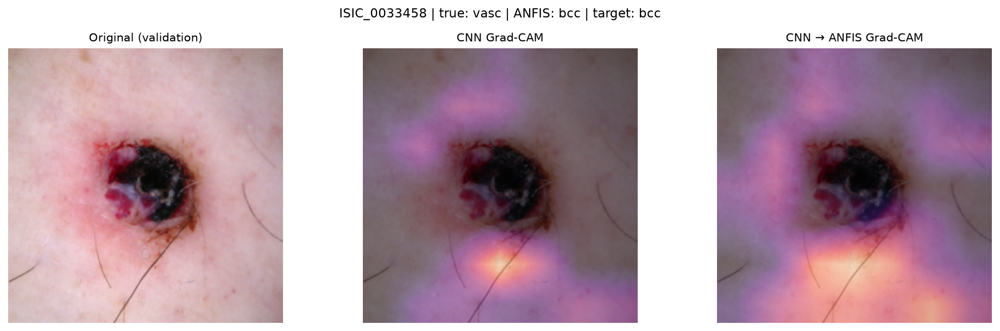

In [14]:

from IPython.display import display, Image as IPImage

# Four actual validation examples from Notebook 10
examples = {
    "ISIC_0032152": "Melanoma false negative",
    "ISIC_0033129": "Correct melanoma prediction",
    "ISIC_0026253": "Correct nevus prediction",
    "ISIC_0033458": "Vascular lesion misclassification"
}

for image_id, description in examples.items():
    path = session.out / "gradcam_overlays" / f"{image_id}.png"

    if path.is_file():
        print(f"\n{image_id} — {description}")
        display(IPImage(filename=str(path)))
    else:
        print(f"Missing figure: {path}")


Total Grad-CAM figures: 13

Image: ISIC_0025783


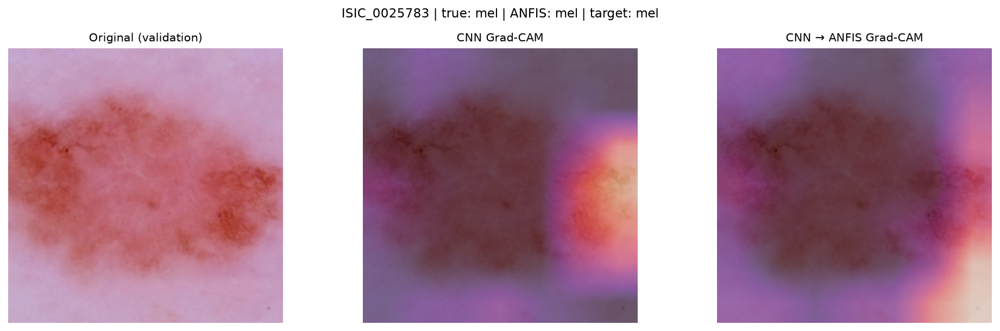


Image: ISIC_0026253


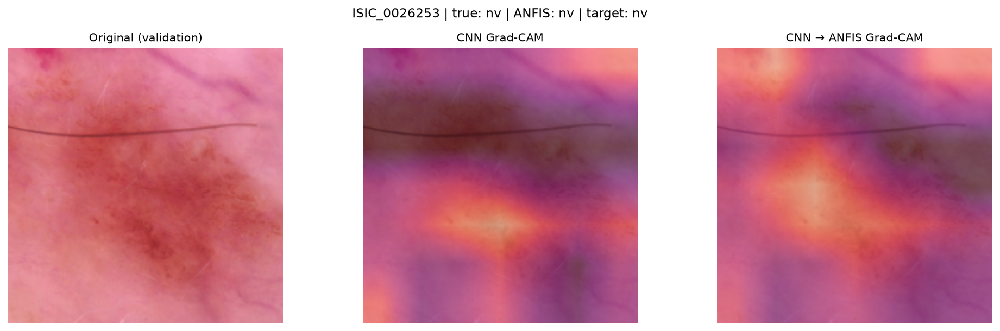


Image: ISIC_0026296


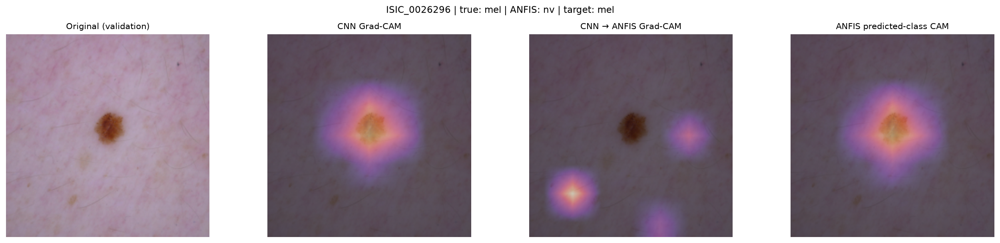


Image: ISIC_0026473


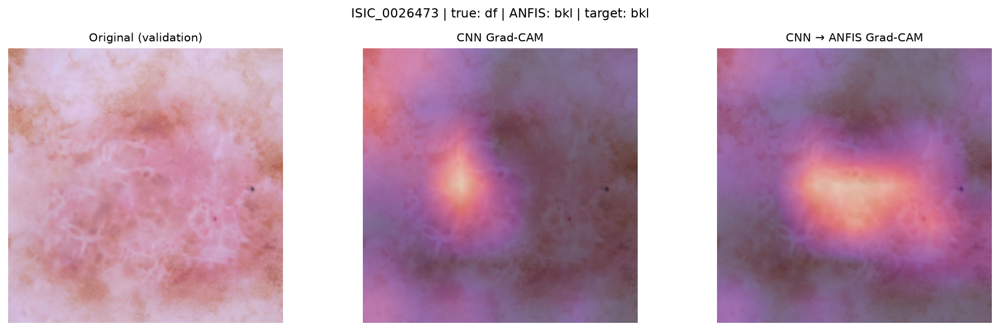


Image: ISIC_0026586


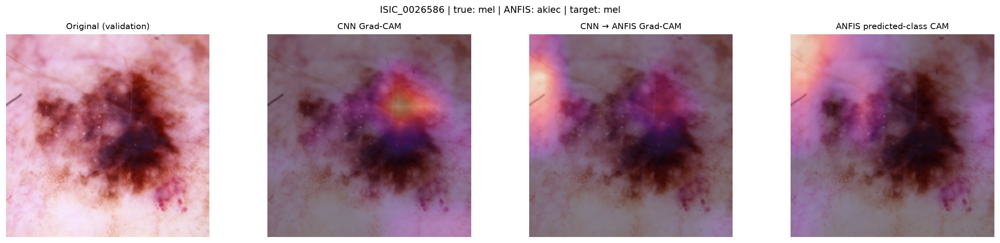


Image: ISIC_0027189


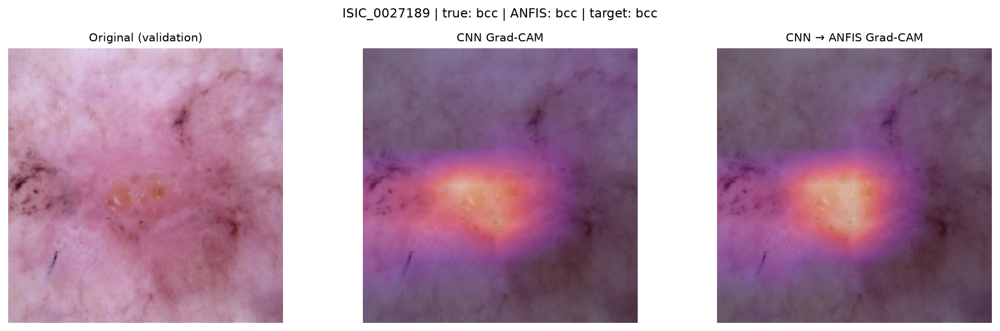


Image: ISIC_0030565


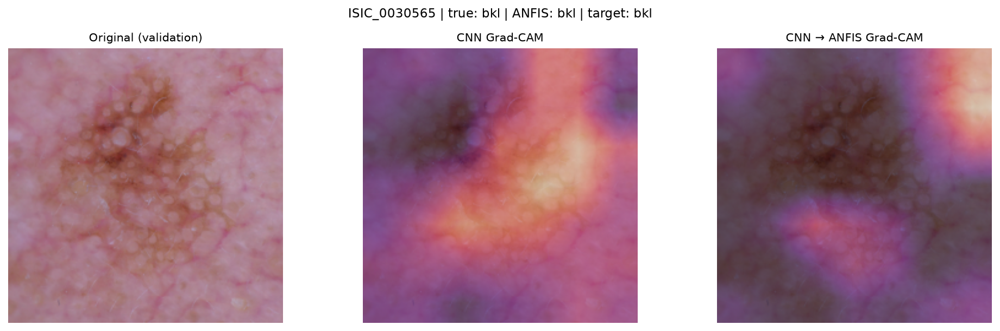


Image: ISIC_0031953


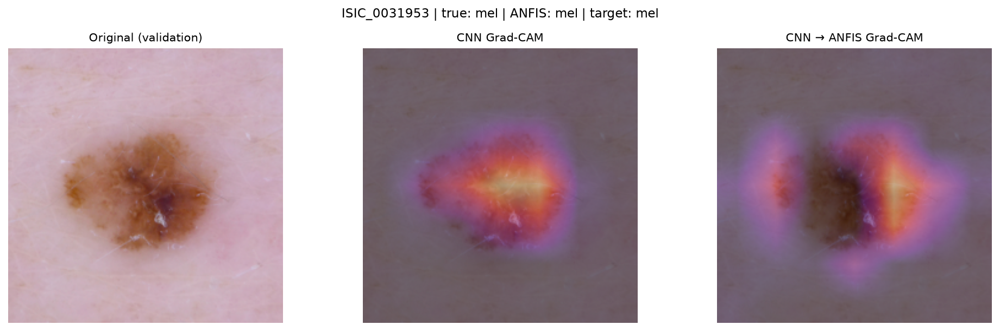


Image: ISIC_0032072


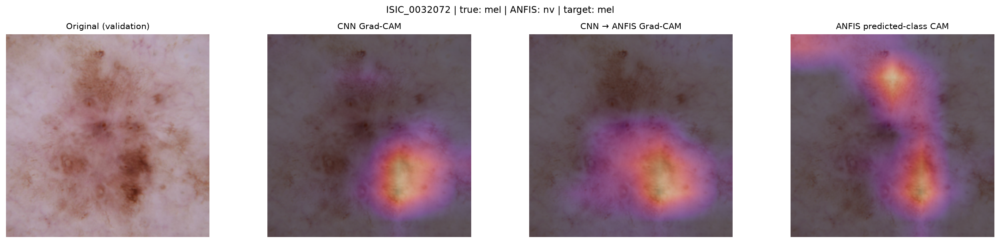


Image: ISIC_0032152


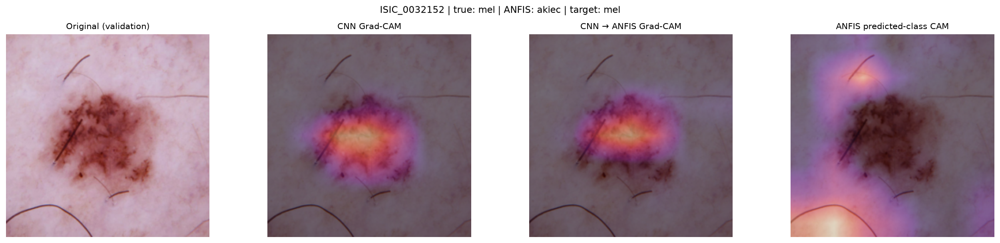


Image: ISIC_0033129


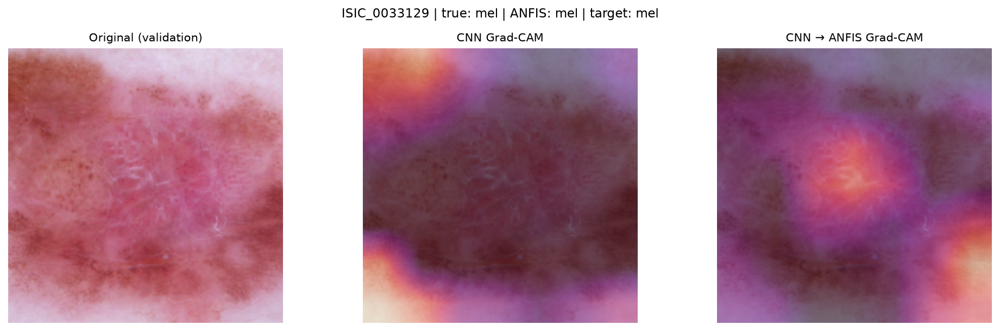


Image: ISIC_0033458


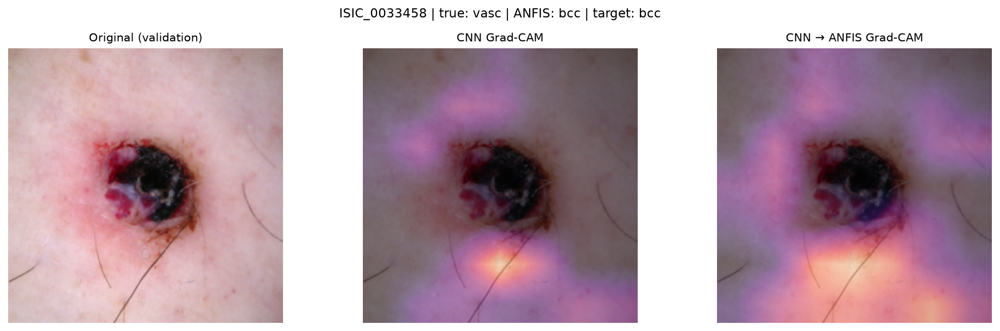


Image: ISIC_0033494


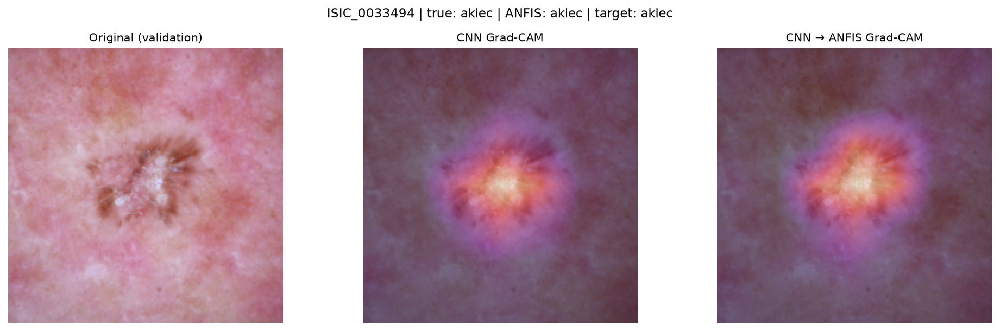

In [15]:

from IPython.display import display, Image as IPImage

gradcam_dir = session.out / "gradcam_overlays"
gradcam_files = sorted(gradcam_dir.glob("*.png"))

print("Total Grad-CAM figures:", len(gradcam_files))

for file in gradcam_files:
    print("\nImage:", file.stem)
    display(IPImage(filename=str(file)))


## 6. Explanation stability

Assess Grad-CAM stability for the **same target class** under ANFIS model seeds **42, 52 and 62** and under a horizontally flipped input transformed back to the original orientation. Compare spatial **Spearman correlation** and top-20%-pixel **intersection-over-union**. Rules themselves are not matched by index across seeds.

In [11]:
stability = evaluate_stability(session, max_images=6, test_horizontal_flip=True)
display(stability.head(10))


                                           spearman              top20_iou  \
                                               mean    std count      mean   
comparison                                                                   
ANFIS16 seed52 original vs hflip-unflipped    0.690  0.108     6     0.505   
ANFIS16 seed52 vs seed42                      0.338  0.343     6     0.323   
ANFIS16 seed52 vs seed62                      0.437  0.388     6     0.416   

                                                         
                                              std count  
comparison                                               
ANFIS16 seed52 original vs hflip-unflipped  0.161     6  
ANFIS16 seed52 vs seed42                    0.155     6  
ANFIS16 seed52 vs seed62                    0.276     6  
NOTE: Rule numbers across random seeds are not comparable without explicit rule alignment.


,image_id,true_dx,comparison,target_class,spearman,top20_iou,flat_a,flat_b
0,ISIC_0032152,mel,ANFIS16 seed52 vs seed42,mel,0.602589,0.441189,False,False
1,ISIC_0032152,mel,ANFIS16 seed52 vs seed62,mel,0.570720,0.507323,False,False
2,ISIC_0032152,mel,ANFIS16 seed52 original vs hflip-unflipped,mel,0.567618,0.358835,False,False
3,ISIC_0026296,mel,ANFIS16 seed52 vs seed42,mel,-0.115483,0.083927,False,False
4,ISIC_0026296,mel,ANFIS16 seed52 vs seed62,mel,-0.075731,0.060950,False,False
5,ISIC_0026296,mel,ANFIS16 seed52 original vs hflip-unflipped,mel,0.623260,0.491417,False,False
6,ISIC_0026586,mel,ANFIS16 seed52 vs seed42,mel,0.316372,0.251481,False,False
7,ISIC_0026586,mel,ANFIS16 seed52 vs seed62,mel,0.720114,0.630249,False,False
8,ISIC_0026586,mel,ANFIS16 seed52 original vs hflip-unflipped,mel,0.873959,0.674454,False,False
9,ISIC_0032072,mel,ANFIS16 seed52 vs seed42,mel,0.557867,0.403104,False,False


## 7. Image-level faithfulness proxy: controlled blur occlusion

Using a **fixed 7×7 tile grid**, blur exactly the same number of high-saliency, low-saliency, or random tiles in the **same validation image**. Compare changes in the fixed target logit and probability using both the original CNN and hybrid ANFIS. A larger drop for top-saliency tiles is a *sensitivity probe*, **not causal/clinical proof**.

Occlusion: ISIC_0032152
Occlusion: ISIC_0026296
Occlusion: ISIC_0026586
Occlusion: ISIC_0032072
Occlusion: ISIC_0033129
Occlusion: ISIC_0031953
Occlusion: ISIC_0025783
Occlusion: ISIC_0026253
 head  fraction_tiles_masked masking  mean_probability_drop  mean_logit_drop  n_images
anfis                    0.1  bottom                 0.0422           0.6184         8
anfis                    0.1  random                 0.0977           1.1129         8
anfis                    0.1     top                 0.2363           1.7684         8
anfis                    0.2  bottom                -0.0764          -0.4337         8
anfis                    0.2  random                 0.1209           1.1814         8
anfis                    0.2     top                 0.3311           2.5141         8
anfis                    0.3  bottom                -0.2448          -0.9873         8
anfis                    0.3  random                 0.1345           1.1373         8
anfis                    

,image_id,lesion_id,sample_group,artifact_type,true_dx,target_class,head,fraction_tiles_masked,masking,original_target_logit,occluded_target_logit,target_logit_drop,original_target_probability,occluded_target_probability,target_probability_drop
0,ISIC_0032152,HAM_0003869,melanoma_FN,,mel,mel,cnn,0.1,top,-0.619593,-1.294125,0.674532,0.085387,0.036833,0.048555
1,ISIC_0032152,HAM_0003869,melanoma_FN,,mel,mel,cnn,0.1,random,-0.619593,-3.253926,2.634333,0.085387,0.013279,0.072109
2,ISIC_0032152,HAM_0003869,melanoma_FN,,mel,mel,cnn,0.1,bottom,-0.619593,0.005543,-0.625137,0.085387,0.124596,-0.039208
3,ISIC_0032152,HAM_0003869,melanoma_FN,,mel,mel,cnn,0.2,top,-0.619593,-0.842735,0.223141,0.085387,0.047755,0.037632
4,ISIC_0032152,HAM_0003869,melanoma_FN,,mel,mel,cnn,0.2,random,-0.619593,0.245434,-0.865028,0.085387,0.328060,-0.242673


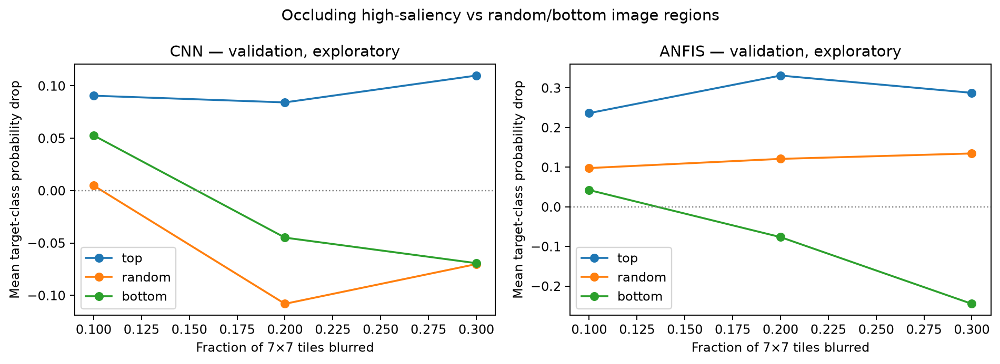

In [12]:
occlusion = evaluate_occlusion(
    session, max_images=8, fractions=(0.10, 0.20, 0.30)
)
display(occlusion.head())
display(IPImage(filename=str(session.out / 'image_occlusion_faithfulness.png')))


## 8. Final output integrity, limitations and backup

Records checkpoint hashes, class order, split SHA, tested image IDs and limitations. The held-out test set stays untouched. No clinical interpretation is made without expert review. Save the output ZIP and notebook before committing the experiment to the team repository.

In [13]:
backup_zip = finalize(session)
print('Complete Notebook 10 output archive:', backup_zip)
print('NEXT: interpret these exploratory results, extend to predeclared samples as feasible, and benchmark efficiency (RQ4).')


Saved: C:\Users\grela\OneDrive\Desktop\OSLOMET\COMPUTATIONAL INTELLIGENCE\FOR FINAL REPORT\CODE\Notebook_10_CNN_ANFIS_XAI_VSCode_Complete\ACIT4620_10_CNN_ANFIS_XAI_VSCode\outputs\ACIT4620_10_Explainability_Validation_Outputs.zip | MB: 9.91
Complete Notebook 10 output archive: C:\Users\grela\OneDrive\Desktop\OSLOMET\COMPUTATIONAL INTELLIGENCE\FOR FINAL REPORT\CODE\Notebook_10_CNN_ANFIS_XAI_VSCode_Complete\ACIT4620_10_CNN_ANFIS_XAI_VSCode\outputs\ACIT4620_10_Explainability_Validation_Outputs.zip
NEXT: interpret these exploratory results, extend to predeclared samples as feasible, and benchmark efficiency (RQ4).
